## 2. Định lý Bayes


In [9]:
def bayes(tien_nghiem, kha_nang, kha_nang_nguoc):
    """Tra ve xac suat hau nghiem.

    tien_nghiem : P(A), niem tin truoc khi co bang chung
    kha_nang : P(B | A), bang chung xuat hien khi A dung
    kha_nang_nguoc : P(B | khong A), bang chung xuat hien khi A sai
    """
    tu_so = kha_nang * tien_nghiem
    mau_so = tu_so + kha_nang_nguoc * (1 - tien_nghiem)
    return tu_so / mau_so


print("Vi du 1: xet nghiem benh")
print(" Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.")
p = bayes(tien_nghiem=0.01, kha_nang=0.99, kha_nang_nguoc=0.01)
print(f" Duong tinh thi kha nang co benh that = {p:.4f}")
print()

# Giữ nguyên chất lượng xét nghiệm, chỉ đổi tỷ lệ mắc bệnh
print("Cung xet nghiem do, doi ty le mac benh:")
print(" Ty le mac benh Hau nghiem khi duong tinh")
for ty_le in [0.001, 0.01, 0.05, 0.10, 0.50]:
    print(f" {ty_le:6.3f} {bayes(ty_le, 0.99, 0.01):.4f}")
print()

print("Vi du 2: hai day chuyen san xuat")
print(" Day A lam 80 phan tram san pham, ty le loi 1 phan tram.")
print(" Day B lam 20 phan tram san pham, ty le loi 5 phan tram.")
# Ở đây "A đúng" nghĩa là sản phẩm đến từ dây B
p_b = bayes(tien_nghiem=0.20, kha_nang=0.05, kha_nang_nguoc=0.01)
print(f" Nhat duoc san pham loi, kha nang no tu day B = {p_b:.4f}")
print()

print("Kiem lai bang cach dem tren 1000 san pham:")
loi_a = 800 * 0.01
loi_b = 200 * 0.05
print(f" Day A: 800 san pham, {loi_a:.0f} cai loi")
print(f" Day B: 200 san pham, {loi_b:.0f} cai loi")
tong_loi = loi_a + loi_b
print(f" Ty le tu day B = {loi_b} / {tong_loi} = {loi_b / tong_loi:.4f}")

Vi du 1: xet nghiem benh
 Ty le mac benh 1 phan tram, xet nghiem dung 99 phan tram.
 Duong tinh thi kha nang co benh that = 0.5000

Cung xet nghiem do, doi ty le mac benh:
 Ty le mac benh Hau nghiem khi duong tinh
  0.001 0.0902
  0.010 0.5000
  0.050 0.8390
  0.100 0.9167
  0.500 0.9900

Vi du 2: hai day chuyen san xuat
 Day A lam 80 phan tram san pham, ty le loi 1 phan tram.
 Day B lam 20 phan tram san pham, ty le loi 5 phan tram.
 Nhat duoc san pham loi, kha nang no tu day B = 0.5556

Kiem lai bang cach dem tren 1000 san pham:
 Day A: 800 san pham, 8 cai loi
 Day B: 200 san pham, 10 cai loi
 Ty le tu day B = 10.0 / 18.0 = 0.5556


##3.Biến văn bản thành số

In [10]:
import os
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

# Tự động tạo thư mục data và di chuyển tệp nếu cần thiết
os.makedirs("data", exist_ok=True)
for f in ["tin_nhan.csv", "sinh_vien.csv"]:
    if os.path.exists(f) and not os.path.exists(f"data/{f}"):
        os.replace(f, f"data/{f}")

df = pd.read_csv("data/tin_nhan.csv")

print("Kích thước bảng:", df.shape)
print()
print("Số tin theo nhãn (1 là rác, 0 là thường):")
print(df["la_rac"].value_counts())
print()
print("Tỷ lệ tin rác:", round(df["la_rac"].mean(), 4))
print()

print("Ba tin nhắn đầu tiên:")
for i in range(3):
    print(f"  [{df.la_rac[i]}] {df.noi_dung[i]}")
print()

# Tách từ bằng khoảng trắng (mặc định của sklearn bỏ từ một ký tự)
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])

print("Kích thước bảng đếm từ:", X.shape)
print("Số từ trong từ điển:", len(vec.vocabulary_))
print()

dem = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())
dem["la_rac"] = df["la_rac"]
tong = dem.groupby("la_rac").sum().T
tong.columns = ["thuong", "rac"]

print("Mười từ xuất hiện nhiều nhất trong tin rác:")
print(tong.sort_values("rac", ascending=False).head(10))
print()
print("Mười từ xuất hiện nhiều nhất trong tin thường:")
print(tong.sort_values("thuong", ascending=False).head(10))

Kích thước bảng: (300, 2)

Số tin theo nhãn (1 là rác, 0 là thường):
la_rac
0    180
1    120
Name: count, dtype: int64

Tỷ lệ tin rác: 0.4

Ba tin nhắn đầu tiên:
  [0] cáo gửi cáo thầy nhóm cáo gửi có cho
  [1] miễn giảm ngay hạn miễn tay nhé thưởng cho nhanh
  [0] cho bạn mai gửi nhóm bài chiều

Kích thước bảng đếm từ: (300, 40)
Số từ trong từ điển: 40

Mười từ xuất hiện nhiều nhất trong tin rác:
       thuong  rac
tay         3   48
ngay        4   47
nhanh       9   44
chót        6   43
giảm        6   42
lúc        39   42
quà         8   41
click       5   40
phí         6   40
miễn        4   39

Mười từ xuất hiện nhiều nhất trong tin thường:
       thuong  rac
thầy       74    7
bài        73    4
cáo        72    8
chiều      68    8
ạ          65    7
tài        64   11
tập        63    6
gửi        61   10
lớp        60    2
nhóm       58    7


## 4. Bộ lọc tin nhắn rác


In [11]:
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB

y = df["la_rac"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print("Số tin để học    :", X_train.shape[0])
print("Số tin để kiểm tra:", X_test.shape[0])
print()

mo_hinh = MultinomialNB(alpha=1.0)
mo_hinh.fit(X_train, y_train)
y_pred = mo_hinh.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print("Ma trận nhầm lẫn")
print(f"  TN = {tn:2d}  thư thường được giữ đúng")
print(f"  FP = {fp:2d}  thư thường bị xoá nhầm")
print(f"  FN = {fn:2d}  thư rác lọt lưới")
print(f"  TP = {tp:2d}  thư rác bị chặn đúng")
print()

print(f"Accuracy  = {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision = {precision_score(y_test, y_pred):.4f}")
print(f"Recall    = {recall_score(y_test, y_pred):.4f}")
print()

# Thử bộ lọc trên vài tin nhắn tự gõ.
# Ba tin gõ không dấu như trong tài liệu; nhiều từ không có trong từ điển
# (từ điển có dấu) nên bị bỏ qua, chỉ các từ như nhanh, tay, click, ngay... được tính.
tin_moi = [
    "trung thuong khuyen mai nhanh tay click ngay",
    "hop nhom bao cao chieu mai phong 305",
    "ban gui giup em tai lieu bai tap nhe",
]
X_moi = vec.transform(tin_moi)
p_rac = mo_hinh.predict_proba(X_moi)[:, 1]

print("Thử trên ba tin nhắn tự gõ:")
for tin, p in zip(tin_moi, p_rac):
    nhan = "RÁC" if p >= 0.5 else "thường"
    print(f"  [{nhan:6s}] p = {p:.4f} <- {tin}")

Số tin để học    : 225
Số tin để kiểm tra: 75

Ma trận nhầm lẫn
  TN = 45  thư thường được giữ đúng
  FP =  0  thư thường bị xoá nhầm
  FN =  4  thư rác lọt lưới
  TP = 26  thư rác bị chặn đúng

Accuracy  = 0.9467
Precision = 1.0000
Recall    = 0.8667

Thử trên ba tin nhắn tự gõ:
  [RÁC   ] p = 0.9992 <- trung thuong khuyen mai nhanh tay click ngay
  [thường] p = 0.0983 <- hop nhom bao cao chieu mai phong 305
  [thường] p = 0.0719 <- ban gui giup em tai lieu bai tap nhe


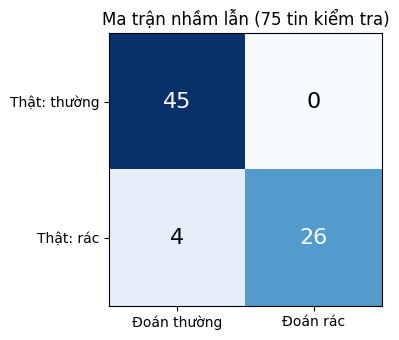

In [12]:
# Vẽ ma trận nhầm lẫn
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(4, 3.5))
ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1]); ax.set_xticklabels(["Đoán thường", "Đoán rác"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["Thật: thường", "Thật: rác"])
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=16)
ax.set_title("Ma trận nhầm lẫn (75 tin kiểm tra)")
plt.tight_layout(); plt.show()

## 5. Vấn đề số không và cách làm trơn
Tự cài Naive Bayes trên kho 6 tin nhắn, không dùng scikit-learn (tệp `d4_lam_tron.py`).

In [13]:
from collections import Counter

kho = [
    ("trung thuong ngay", 1),
    ("khuyen mai giam gia", 1),
    ("trung thuong click", 1),
    ("hop nhom chieu mai", 0),
    ("bai tap nhom nop mai", 0),
    ("thay gui tai lieu", 0),
]

tu_dien = sorted({t for cau, _ in kho for t in cau.split()})
V = len(tu_dien)
print(f"Từ điển có {V} từ:")
for i in range(0, V, 9):
    print("  " + " ".join(tu_dien[i:i + 9]))
print()

dem = {0: Counter(), 1: Counter()}
tong = {0: 0, 1: 0}
for cau, nhan in kho:
    for t in cau.split():
        dem[nhan][t] += 1
        tong[nhan] += 1

print("Số lần xuất hiện của từng từ")
print(f"  {'từ':12s} {'rác':>5s} {'thường':>7s}")
for t in tu_dien:
    print(f"  {t:12s} {dem[1][t]:5d} {dem[0][t]:7d}")
print()


def xac_suat(tu, nhan, alpha):
    """P(từ | nhãn) có làm trơn Laplace với hệ số alpha."""
    return (dem[nhan][tu] + alpha) / (tong[nhan] + alpha * V)


def diem(cau, nhan, alpha):
    """Tích của xác suất tiên nghiệm và các xác suất từ."""
    p = 0.5  # hai lớp cân bằng nên tiên nghiệm bằng nhau
    for t in cau.split():
        if t in tu_dien:
            p *= xac_suat(t, nhan, alpha)
    return p


cau_thu = "trung thuong bai tap"
print(f'Tin nhắn thử: "{cau_thu}"')
print("Từ 'bai' chỉ xuất hiện ở lớp thường, chưa bao giờ ở lớp rác.")
print()

for alpha in [0.0, 1.0]:
    d_rac = diem(cau_thu, 1, alpha)
    d_thuong = diem(cau_thu, 0, alpha)
    ket = "rác" if d_rac > d_thuong else "thường"
    print(f"alpha = {alpha}")
    print(f"  điểm lớp rác    = {d_rac:.10f}")
    print(f"  điểm lớp thường = {d_thuong:.10f}")
    print(f"  kết luận        = {ket}")
    print()

print("Không làm trơn, CẢ HAI điểm đều bằng 0 nên mô hình tê liệt (code chọn 'thường' chỉ vì so sánh 0 > 0 là sai).")
print("Lớp rác bằng 0 vì từ 'bai' chưa từng xuất hiện ở lớp rác.")
print("Lớp thường bằng 0 vì từ 'trung' chưa từng xuất hiện ở lớp thường.")
print("Có làm trơn, điểm lớp rác lớn hơn và mô hình kết luận đúng.")

Từ điển có 18 từ:
  bai chieu click gia giam gui hop khuyen lieu
  mai ngay nhom nop tai tap thay thuong trung

Số lần xuất hiện của từng từ
  từ             rác  thường
  bai              0       1
  chieu            0       1
  click            1       0
  gia              1       0
  giam             1       0
  gui              0       1
  hop              0       1
  khuyen           1       0
  lieu             0       1
  mai              1       2
  ngay             1       0
  nhom             0       2
  nop              0       1
  tai              0       1
  tap              0       1
  thay             0       1
  thuong           2       0
  trung            2       0

Tin nhắn thử: "trung thuong bai tap"
Từ 'bai' chỉ xuất hiện ở lớp thường, chưa bao giờ ở lớp rác.

alpha = 0.0
  điểm lớp rác    = 0.0000000000
  điểm lớp thường = 0.0000000000
  kết luận        = thường

alpha = 1.0
  điểm lớp rác    = 0.0000073212
  điểm lớp thường = 0.0000021656
  kết luận        = rác


## 6. Naive Bayes cho số liệu liên tục
`GaussianNB` đặt cạnh hồi quy logistic trên dữ liệu sinh viên (tệp `d5_gaussian.py`).

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

sv = pd.read_csv("data/sinh_vien.csv")
Xs = sv[["gio_on", "diem_giua_ky"]]
ys = sv["qua_mon"]

Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys, test_size=0.25, random_state=17, stratify=ys
)

for ten, m in [("Naive Bayes     ", GaussianNB()),
               ("Hồi quy logistic", LogisticRegression())]:
    m.fit(Xs_train, ys_train)
    acc = accuracy_score(ys_test, m.predict(Xs_test))
    print(f"{ten}: accuracy = {acc:.4f}")
print()

gnb = GaussianNB().fit(Xs_train, ys_train)

print("Những gì Naive Bayes học được")
print(f"  {'':16s} {'gio_on':>10s} {'diem_giua_ky':>14s}")
for i, ten_lop in enumerate(["Lớp 0 (rớt) ", "Lớp 1 (qua) "]):
    tb = gnb.theta_[i]
    dl = gnb.var_[i] ** 0.5
    print(f"  {ten_lop:16s} trung bình {tb[0]:8.2f} {tb[1]:14.2f}")
    print(f"  {'':16s} độ lệch    {dl[0]:8.2f} {dl[1]:14.2f}")
print()

ty_le = ", ".join(f"{float(v):.4f}" for v in gnb.class_prior_)
print(f"Tỷ lệ từng lớp trong tập học: {ty_le}")
print()

ban_moi = pd.DataFrame({"gio_on": [5, 13, 20, 28],
                        "diem_giua_ky": [4.0, 6.0, 7.0, 9.0]})
p = gnb.predict_proba(ban_moi)[:, 1]
print("Dự đoán cho bốn bạn mới:")
print(f"  {'giờ ôn':>8s} {'điểm GK':>9s} {'P(qua môn)':>12s}")
for (_, r), pi in zip(ban_moi.iterrows(), p):
    print(f"  {r.gio_on:8.0f} {r.diem_giua_ky:9.1f} {pi:12.4f}")

Naive Bayes     : accuracy = 0.9000
Hồi quy logistic: accuracy = 0.9000

Những gì Naive Bayes học được
                       gio_on   diem_giua_ky
  Lớp 0 (rớt)      trung bình     8.18           3.99
                   độ lệch        5.29           1.92
  Lớp 1 (qua)      trung bình    20.03           6.70
                   độ lệch        5.81           1.50

Tỷ lệ từng lớp trong tập học: 0.4111, 0.5889

Dự đoán cho bốn bạn mới:
    giờ ôn   điểm GK   P(qua môn)
         5       4.0       0.0137
        13       6.0       0.6550
        20       7.0       0.9855
        28       9.0       0.9999


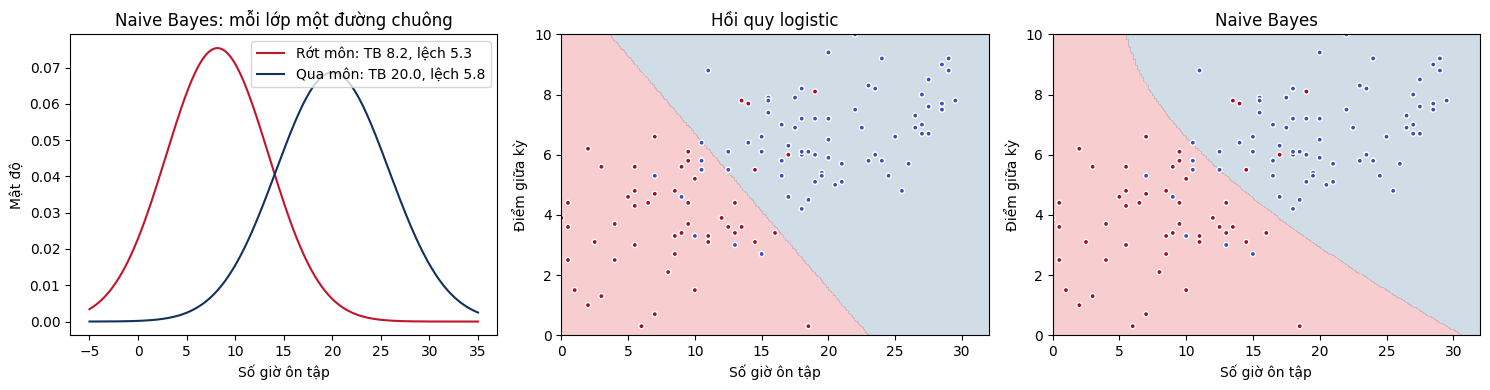

In [15]:
# Hình 4 và 5: đường chuông của từng lớp và biên quyết định hai mô hình
import numpy as np

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

x = np.linspace(-5, 35, 400)
for i, (ten, mau) in enumerate([("Rớt môn", "#c0152a"), ("Qua môn", "#12315c")]):
    mu, sd = gnb.theta_[i][0], gnb.var_[i][0] ** 0.5
    ax[0].plot(x, np.exp(-0.5 * ((x - mu) / sd) ** 2) / (sd * np.sqrt(2 * np.pi)),
               color=mau, label=f"{ten}: TB {mu:.1f}, lệch {sd:.1f}")
ax[0].set_xlabel("Số giờ ôn tập"); ax[0].set_ylabel("Mật độ")
ax[0].set_title("Naive Bayes: mỗi lớp một đường chuông"); ax[0].legend()

lg = LogisticRegression().fit(Xs_train, ys_train)
gx, gy = np.meshgrid(np.linspace(0, 32, 200), np.linspace(0, 10, 200))
lưới = pd.DataFrame({"gio_on": gx.ravel(), "diem_giua_ky": gy.ravel()})
for a, m, ten in [(ax[1], lg, "Hồi quy logistic"), (ax[2], gnb, "Naive Bayes")]:
    a.contourf(gx, gy, m.predict(lưới).reshape(gx.shape), alpha=0.25,
               levels=[-0.5, 0.5, 1.5], colors=["#e63946", "#457b9d"])
    a.scatter(sv.gio_on, sv.diem_giua_ky, c=sv.qua_mon, cmap="coolwarm_r", s=14, edgecolor="white")
    a.set_title(ten); a.set_xlabel("Số giờ ôn tập"); a.set_ylabel("Điểm giữa kỳ")
plt.tight_layout(); plt.show()

### 6.4. Khi dữ liệu ít, Naive Bayes vượt hồi quy logistic
Tài liệu nêu số liệu này (Hình 6). Đoạn dưới tự đo lại: với mỗi cỡ tập huấn luyện, lấy ngẫu nhiên nhiều lần rồi tính accuracy trung bình trên tập kiểm tra bài lọc tin rác. Kết quả có thể lệch nhẹ so với tài liệu vì tài liệu không nói rõ cách lấy mẫu.

n =  10: Naive Bayes 0.9067 | Logistic 0.8627
n =  20: Naive Bayes 0.9333 | Logistic 0.9044
n =  30: Naive Bayes 0.9373 | Logistic 0.9133
n =  50: Naive Bayes 0.9444 | Logistic 0.9236
n =  80: Naive Bayes 0.9449 | Logistic 0.9240
n = 150: Naive Bayes 0.9467 | Logistic 0.9267
n = 225: Naive Bayes 0.9467 | Logistic 0.9200


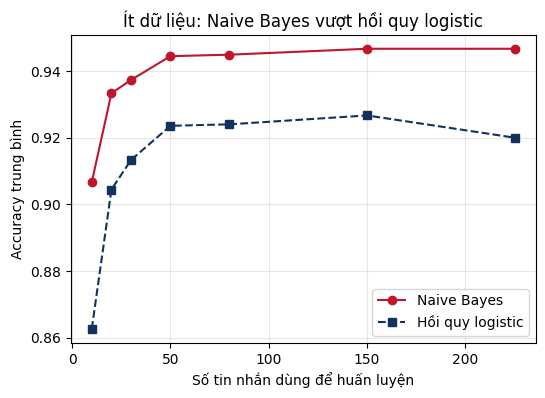

In [16]:
cac_co = [10, 20, 30, 50, 80, 150, 225]
acc_nb, acc_lr = [], []

for n in cac_co:
    a_nb, a_lr = [], []
    lan = 1 if n == X_train.shape[0] else 30
    for seed in range(lan):
        if n == X_train.shape[0]:
            Xn, yn = X_train, y_train
        else:
            Xn, _, yn, _ = train_test_split(X_train, y_train, train_size=n,
                                            stratify=y_train, random_state=seed)
        a_nb.append(accuracy_score(y_test, MultinomialNB().fit(Xn, yn).predict(X_test)))
        a_lr.append(accuracy_score(y_test, LogisticRegression(max_iter=1000).fit(Xn, yn).predict(X_test)))
    acc_nb.append(np.mean(a_nb)); acc_lr.append(np.mean(a_lr))
    print(f"n = {n:3d}: Naive Bayes {acc_nb[-1]:.4f} | Logistic {acc_lr[-1]:.4f}")

plt.figure(figsize=(6, 4))
plt.plot(cac_co, acc_nb, "o-", color="#c0152a", label="Naive Bayes")
plt.plot(cac_co, acc_lr, "s--", color="#12315c", label="Hồi quy logistic")
plt.xlabel("Số tin nhắn dùng để huấn luyện"); plt.ylabel("Accuracy trung bình")
plt.title("Ít dữ liệu: Naive Bayes vượt hồi quy logistic")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 7. Bài tập

### Bài tập 1: Bayes với ba nguyên nhân
Ba nhóm: học đều 50%, học dồn 30%, ít học 20%. Tỷ lệ qua môn lần lượt 0.95, 0.70, 0.30. Biết một bạn đã qua môn, tính xác suất bạn đó thuộc từng nhóm.

In [17]:
def bayes_nhieu_nhanh(tien_nghiem, kha_nang):
    """Mở rộng hàm bayes cho nhiều nguyên nhân.

    tien_nghiem : danh sách P(nhóm k)
    kha_nang    : danh sách P(bằng chứng | nhóm k)
    Trả về danh sách P(nhóm k | bằng chứng).
    """
    tu_so = [p * l for p, l in zip(tien_nghiem, kha_nang)]
    mau_so = sum(tu_so)          # công thức xác suất toàn phần
    return [t / mau_so for t in tu_so]


nhom = ["Học đều", "Học dồn", "Ít học"]
hau_nghiem = bayes_nhieu_nhanh([0.50, 0.30, 0.20], [0.95, 0.70, 0.30])

print("Biết bạn đó đã qua môn:")
for ten, p in zip(nhom, hau_nghiem):
    print(f"  P({ten:8s} | qua môn) = {p:.4f}")
print(f"Tổng ba xác suất = {sum(hau_nghiem):.4f}  (phải bằng 1)")
print(f"Tỷ lệ qua môn chung P(qua) = {0.5*0.95 + 0.3*0.70 + 0.2*0.30:.4f}")

Biết bạn đó đã qua môn:
  P(Học đều  | qua môn) = 0.6376
  P(Học dồn  | qua môn) = 0.2819
  P(Ít học   | qua môn) = 0.0805
Tổng ba xác suất = 1.0000  (phải bằng 1)
Tỷ lệ qua môn chung P(qua) = 0.7450


**Nhận xét:** nhóm học đều chiếm khoảng 64% số bạn qua môn, cao hơn tiên nghiệm 50% của nó vì tỷ lệ qua môn của nhóm này cao nhất. Nhóm ít học tụt từ 20% xuống còn khoảng 8%.

### Bài tập 2: Từ nào tố cáo mạnh nhất
Dùng `feature_log_prob_` tính hiệu hai lớp cho từng từ.

5 từ tố cáo tin RÁC mạnh nhất:
   từ  chênh lệch
  mãi    3.203435
  tay    2.905600
 ngay    2.661837
 miễn    2.479516
trúng    2.374155

5 từ cho thấy tin THƯỜNG mạnh nhất:
   từ  chênh lệch
  lớp   -2.612187
   em   -2.561756
  bài   -2.294553
phòng   -2.274074
  báo   -2.274074


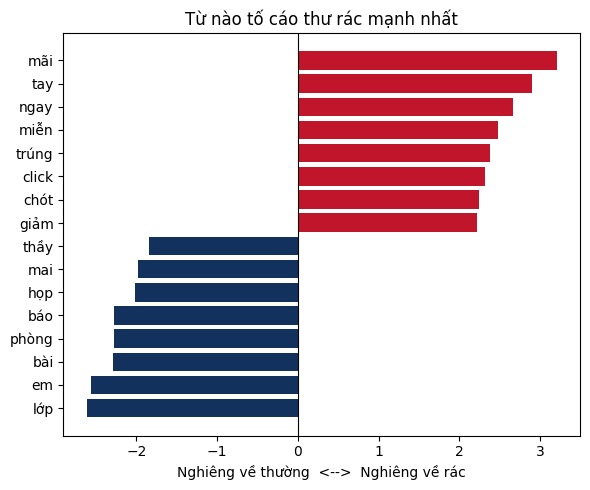

In [18]:
mo_hinh_full = MultinomialNB().fit(X, y)       # huấn luyện trên toàn bộ 300 tin
chenh = mo_hinh_full.feature_log_prob_[1] - mo_hinh_full.feature_log_prob_[0]
tu = vec.get_feature_names_out()

bang = pd.DataFrame({"từ": tu, "chênh lệch": chenh}).sort_values("chênh lệch", ascending=False)

print("5 từ tố cáo tin RÁC mạnh nhất:")
print(bang.head(5).to_string(index=False))
print()
print("5 từ cho thấy tin THƯỜNG mạnh nhất:")
print(bang.tail(5).iloc[::-1].to_string(index=False))

# Vẽ giống Hình 1
top = pd.concat([bang.head(8), bang.tail(8)])
plt.figure(figsize=(6, 5))
plt.barh(top["từ"], top["chênh lệch"],
         color=["#c0152a" if v > 0 else "#12315c" for v in top["chênh lệch"]])
plt.gca().invert_yaxis()
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Nghiêng về thường  <-->  Nghiêng về rác")
plt.title("Từ nào tố cáo thư rác mạnh nhất"); plt.tight_layout(); plt.show()

### Bài tập 3: Đổi tham số làm trơn
Chạy lại bộ lọc với alpha = 0.001, 0.1, 1.0, 10.0, 100.0.

In [19]:
print(f"{'alpha':>8s} {'Accuracy':>9s} {'Precision':>10s} {'Recall':>8s}")
for a in [0.001, 0.1, 1.0, 10.0, 100.0]:
    m = MultinomialNB(alpha=a).fit(X_train, y_train)
    yp = m.predict(X_test)
    print(f"{a:8g} {accuracy_score(y_test, yp):9.4f} "
          f"{precision_score(y_test, yp, zero_division=0):10.4f} "
          f"{recall_score(y_test, yp):8.4f}")

# Bằng chứng ở mức xác suất: alpha lớn kéo xác suất các từ lại gần nhau
print()
print("Độ chênh lệch trung bình |log P(từ|rác) - log P(từ|thường)| giữa hai lớp:")
for a in [0.001, 0.1, 1.0, 10.0, 100.0, 10000.0]:
    m = MultinomialNB(alpha=a).fit(X_train, y_train)
    do_chenh = np.abs(m.feature_log_prob_[1] - m.feature_log_prob_[0]).mean()
    yp = m.predict(X_test)
    print(f"  alpha = {a:>8g}: chênh lệch TB = {do_chenh:.4f} | recall = {recall_score(y_test, yp):.4f}")

   alpha  Accuracy  Precision   Recall
   0.001    0.9467     1.0000   0.8667
     0.1    0.9467     1.0000   0.8667
       1    0.9467     1.0000   0.8667
      10    0.9467     1.0000   0.8667
     100    0.9467     1.0000   0.8667

Độ chênh lệch trung bình |log P(từ|rác) - log P(từ|thường)| giữa hai lớp:
  alpha =    0.001: chênh lệch TB = 1.8574 | recall = 0.8667
  alpha =      0.1: chênh lệch TB = 1.8353 | recall = 0.8667
  alpha =        1: chênh lệch TB = 1.6680 | recall = 0.8667
  alpha =       10: chênh lệch TB = 0.9763 | recall = 0.8667
  alpha =      100: chênh lệch TB = 0.2250 | recall = 0.8667
  alpha =    10000: chênh lệch TB = 0.0027 | recall = 0.0000


**Nhận xét:** trên bộ dữ liệu mô phỏng này, hai lớp tách rất rõ nên accuracy, precision và recall gần như không đổi khi alpha từ 0.001 đến 100. Tuy vậy bảng thứ hai cho thấy cơ chế: alpha càng lớn thì phần cộng thêm `alpha` càng át số đếm thật, xác suất của mọi từ xích lại gần nhau (gần `1/V`), nên độ chênh lệch giữa hai lớp co lại. Khi alpha rất lớn, các từ không còn phân biệt được hai lớp, mô hình chỉ còn dựa vào tiên nghiệm và sẽ đoán thiên về lớp đông hơn (lớp thường), làm recall tụt. Hãy đọc kết quả thật in ra ở trên để kiểm chứng chỗ nào bắt đầu thay đổi.

### Bài tập 4: Tự viết bộ lọc không dùng thư viện
Tự đếm từ, tự làm trơn, tính điểm bằng tổng loga, rồi so với `MultinomialNB` trên cùng cách chia (`random_state=17`).

In [20]:
import math
from collections import Counter


class LocThuRacTuViet:
    """Naive Bayes đa thức tự cài, làm trơn Laplace, tính bằng tổng loga."""

    def __init__(self, alpha=1.0):
        self.alpha = alpha

    def fit(self, cac_tin, cac_nhan, tu_dien):
        self.tu_dien = set(tu_dien)
        self.V = len(self.tu_dien)
        self.lop = sorted(set(cac_nhan))
        self.dem = {k: Counter() for k in self.lop}
        self.tong = {k: 0 for k in self.lop}
        so_tin = Counter(cac_nhan)
        self.log_tien_nghiem = {k: math.log(so_tin[k] / len(cac_nhan)) for k in self.lop}
        for tin, k in zip(cac_tin, cac_nhan):
            for t in tin.split():
                if t in self.tu_dien:
                    self.dem[k][t] += 1
                    self.tong[k] += 1
        return self

    def _log_xs(self, t, k):
        return math.log((self.dem[k][t] + self.alpha) / (self.tong[k] + self.alpha * self.V))

    def diem(self, tin, k):
        # log P(y) + tổng log P(từ | y); bỏ qua từ ngoài từ điển
        return self.log_tien_nghiem[k] + sum(
            self._log_xs(t, k) for t in tin.split() if t in self.tu_dien)

    def predict(self, cac_tin):
        return [max(self.lop, key=lambda k: self.diem(tin, k)) for tin in cac_tin]


# Cùng cách chia như MultinomialNB: random_state=17, stratify theo nhãn
tin_train, tin_test, nhan_train, nhan_test = train_test_split(
    df["noi_dung"].tolist(), df["la_rac"].tolist(),
    test_size=0.25, random_state=17, stratify=df["la_rac"]
)

# Từ điển lấy từ toàn bộ kho, giống CountVectorizer ở trên
tu_dien_full = {t for tin in df["noi_dung"] for t in tin.split()}

loc = LocThuRacTuViet(alpha=1.0).fit(tin_train, nhan_train, tu_dien_full)
du_doan_tu_viet = loc.predict(tin_test)

acc_tu_viet = accuracy_score(nhan_test, du_doan_tu_viet)
acc_sklearn = accuracy_score(y_test, MultinomialNB(alpha=1.0).fit(X_train, y_train).predict(X_test))

print(f"Accuracy bộ lọc tự viết : {acc_tu_viet:.4f}")
print(f"Accuracy MultinomialNB  : {acc_sklearn:.4f}")
print("Hai kết quả khớp nhau" if abs(acc_tu_viet - acc_sklearn) < 1e-9 else "Có lệch, hãy kiểm tra lại mã")
print("Số tin dự đoán khác nhau:",
      int((np.array(du_doan_tu_viet) != MultinomialNB().fit(X_train, y_train).predict(X_test)).sum()))

Accuracy bộ lọc tự viết : 0.9467
Accuracy MultinomialNB  : 0.9467
Hai kết quả khớp nhau
Số tin dự đoán khác nhau: 0


### Bài tập 5: Chọn sai biến thể Naive Bayes


In [21]:
print("Giá trị nhỏ nhất của hai cột:", Xs.min().to_dict())

try:
    m_sai = MultinomialNB().fit(Xs_train, ys_train)
    acc_sai = accuracy_score(ys_test, m_sai.predict(Xs_test))
    print(f"MultinomialNB: accuracy = {acc_sai:.4f}   (không báo lỗi)")
except ValueError as e:
    print("MultinomialNB báo lỗi:", e)

acc_dung = accuracy_score(ys_test, GaussianNB().fit(Xs_train, ys_train).predict(Xs_test))
print(f"GaussianNB   : accuracy = {acc_dung:.4f}")

Giá trị nhỏ nhất của hai cột: {'gio_on': 0.0, 'diem_giua_ky': 0.3}
MultinomialNB: accuracy = 0.8000   (không báo lỗi)
GaussianNB   : accuracy = 0.9000


**Giải thích:** `MultinomialNB` giả định mỗi đặc trưng là một số đếm (số lần một sự kiện xảy ra) và ước lượng xác suất bằng tỷ lệ tổng các số đếm. Số giờ ôn và điểm giữa kỳ là số thực liên tục, không phải số đếm, nên mô hình hiểu sai bản chất dữ liệu (ví dụ coi 20 giờ như "từ xuất hiện 20 lần"). Chỉ khi dữ liệu không âm thì nó mới chạy, nên không báo lỗi, và accuracy vẫn ra một con số nhìn có vẻ chấp nhận được (0.80, thấp hơn 0.90 của GaussianNB). Đây là lỗi im lặng: chạy trơn nhưng sai về nguyên tắc, và nó không dùng được thông tin về trung bình, độ lệch của từng lớp như `GaussianNB`.

### Bài tập 6: Lớp hiếm và xác suất tiên nghiệm


In [22]:
thuong = df[df["la_rac"] == 0]
rac_it = df[df["la_rac"] == 1].head(20)
df_lech = pd.concat([thuong, rac_it]).reset_index(drop=True)

print("Phân bố nhãn bộ mất cân bằng:")
print(df_lech["la_rac"].value_counts())
print()

vec_l = CountVectorizer(token_pattern=r"(?u)\S+")
X_l = vec_l.fit_transform(df_lech["noi_dung"])
y_l = df_lech["la_rac"]

Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_l, y_l, test_size=0.25, random_state=17, stratify=y_l
)
m_l = MultinomialNB(alpha=1.0).fit(Xl_train, yl_train)
yl_pred = m_l.predict(Xl_test)

print(f"Số tin rác trong tập kiểm tra: {int((yl_test == 1).sum())}")
print(f"Accuracy       = {accuracy_score(yl_test, yl_pred):.4f}")
print(f"Recall lớp rác = {recall_score(yl_test, yl_pred, pos_label=1):.4f}")
print(f"Precision rác  = {precision_score(yl_test, yl_pred, pos_label=1, zero_division=0):.4f}")
print(f"Tiên nghiệm lớp (thường, rác) = {np.round(np.exp(m_l.class_log_prior_), 4)}")
print()
print("Nếu luôn đoán 'thường', accuracy sẽ là:", round((yl_test == 0).mean(), 4))
print(confusion_matrix(yl_test, yl_pred))

Phân bố nhãn bộ mất cân bằng:
la_rac
0    180
1     20
Name: count, dtype: int64

Số tin rác trong tập kiểm tra: 5
Accuracy       = 0.9800
Recall lớp rác = 0.8000
Precision rác  = 1.0000
Tiên nghiệm lớp (thường, rác) = [0.9 0.1]

Nếu luôn đoán 'thường', accuracy sẽ là: 0.9
[[45  0]
 [ 1  4]]


**Nhận xét:** lớp rác chỉ còn khoảng 10% dữ liệu nên tiên nghiệm của nó rất nhỏ (0.1) và bị nhân vào mọi điểm số, khiến mô hình khó chọn lớp rác. Accuracy lên 0.98, cao hơn bộ cân bằng (0.9467), nhưng đó là ảo giác: chỉ cần đoán "thường" cho tất cả đã đúng khoảng 90%. Recall của lớp rác (0.80, thấp hơn 0.8667 của bộ cân bằng và đo trên chỉ 5 tin rác) mới phản ánh đúng bộ lọc bỏ sót bao nhiêu tin rác. Vì vậy với dữ liệu mất cân bằng không được chỉ nhìn accuracy, mà phải xem recall của lớp hiếm.